
# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?



--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [2]:
# importar librerias
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:

# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [4]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


In [6]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [7]:

# revisar el número de filas y columnas de cada dataset
print("plans:", plans.shape)
print("users:", users.shape)
print("usage:", usage.shape)

plans: (2, 8)
users: (4000, 8)
usage: (40000, 6)


In [8]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [9]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [10]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [11]:
# cantidad de nulos para users
print("Cantidad de valores nulos")
print(users.isnull().sum())

print("\nProporción de valores nulos (%)")
print((users.isnull().mean() * 100).round(2))

Cantidad de valores nulos
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos (%)
user_id        0.00
first_name     0.00
last_name      0.00
age            0.00
city          11.72
reg_date       0.00
plan           0.00
churn_date    88.35
dtype: float64


In [12]:
# cantidad de nulos para usage
print("Cantidad de valores nulos")
print(usage.isnull().sum())

print("\nProporción de valores nulos (%)")
print((usage.isnull().mean() * 100).round(2))

Cantidad de valores nulos
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos (%)
id           0.00
user_id      0.00
type         0.00
date         0.12
duration    55.19
length      44.74
dtype: float64



plans: No presenta valores nulos. No requiere ninguna acción.

users.city: Tiene 469 valores nulos (11,72 %). Investigar su origen y mantenerlos como nulos si no existe información confiable para imputarlos.

users.churn_date: Tiene 3.534 valores nulos (88,35 %). Verificar si corresponden a clientes activos; no eliminarlos ni imputarlos automáticamente, pues podrían indicar que no han cancelado el servicio.

usage.date: Tiene 50 valores nulos (0,12 %). Investigar si se pueden recuperar; si no, conservarlos para análisis generales y excluirlos únicamente de análisis que requieran fechas válidas.

usage.duration: Tiene 22.076 valores nulos (55,19 %). Verificar si corresponden a mensajes, donde la duración no aplica; no imputarlos antes de comprobarlo.

usage.length: Tiene 17.896 valores nulos (44,74 %). Verificar si corresponden a llamadas, donde la longitud del mensaje no aplica; no imputarlos antes de comprobarlo.

Los valores faltantes deben tratarse según el significado de cada variable. Se recomienda investigar su causa antes de imputar o eliminar registros, evitando perder información válida o introducir datos artificiales.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [13]:

# explorar columnas numéricas de users
users[['user_id', 'age']].describe()


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id`ontiene 4.000 registros, con valores entre 10.000 y 13.999. No presenta valores faltantes en el resumen. Se debe comprobar que los identificadores sean únicos.
- La columna `age`presenta un valor mínimo de -999, que es una edad inválida y probablemente un valor centinela. Se debe investigar cuántos registros contienen este valor y reemplazarlo por un valor nulo (NaN) antes de decidir si se puede imputar o si debe excluirse de ciertos análisis.

In [14]:
# explorar columnas numéricas de usage
usage[['id', 'user_id', 'duration', 'length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_idambas contienen 40.000 registros. id tiene valores entre 1 y 40.000, mientras que user_id va de 10.000 a 13.999. Estos rangos parecen coherentes con identificadores; se debe verificar que id sea único y que los user_id correspondan a clientes existentes.
- La columna duration: tiene 17.924 valores no nulos, con mínimo de 0 y máximo de 120 minutos. No se observan valores negativos en el resumen, pero se deben investigar las duraciones iguales a cero y los valores extremos para determinar si son válidos.

La columna length: tiene 22.104 valores no nulos, con mínimo de 0 y máximo de 1.490. Se recomienda investigar los valores iguales a cero y el máximo, ya que podrían representar mensajes excepcionalmente largos o errores de registro.

In [15]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for columna in columnas_user:
    print(f"\nValores únicos de {columna}:")
    print(users[columna].value_counts(dropna=False))



Valores únicos de city:
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Valores únicos de plan:
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city` presenta 7 categorías, incluyendo 469 valores nulos y 96 registros con el valor ?. Estos últimos probablemente representan datos desconocidos o centinelas. Se recomienda investigar el significado de ? y estandarizarlo como valor nulo para evitar tratarlo como una ciudad válida.
- La columna `plan`  contiene dos categorías: Basico (2.595 clientes) y Premium (1.405 clientes). Los valores coinciden con los planes observados en el catálogo plans, por lo que no se identifican inconsistencias categóricas en esta revisión.

In [16]:

# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` ontiene dos categorías: text con 22.092 registros y call con 17.908 registros. Ambas categorías corresponden a los tipos de actividad esperados. No se observan categorías adicionales ni valores nulos, por lo que no se requiere una corrección categórica en esta etapa.


users.age: se identificó un valor mínimo de -999, que representa una edad inválida y probablemente un sentinel. Recomiendo contar los registros afectados y reemplazar este valor por NaN para evitar sesgos en el análisis de edades.

users.city: se encontraron 96 registros con el valor ?, que podría representar una ciudad desconocida. Recomiendo confirmar su significado y, si corresponde, reemplazarlo por NaN, conservando los datos originales de los clientes.

users.user_id: los identificadores presentan un rango entre 10.000 y 13.999. Recomiendo verificar que sean únicos y consistentes, sin modificarlos si son válidos.

usage.duration: presenta un máximo de 120 minutos y valores mínimos de cero. Recomiendo investigar las duraciones iguales a cero y los valores extremos para determinar si son registros válidos o errores, sin eliminarlos automáticamente.

usage.length: presenta un máximo de 1.490 y valores mínimos de cero. Recomiendo revisar los mensajes con longitudes extremas y los valores iguales a cero antes de decidir si requieren corrección.

usage.type: contiene únicamente las categorías text y call, que corresponden a los tipos de actividad esperados. No se identificaron valores categóricos inválidos en esta revisión.

los principales posibles sentinels identificados son -999 en age y ? en city. Los valores extremos de duration y length requieren validación adicional antes de clasificarlos como errores. No se deben eliminar ni modificar registros sin comprobar primero su significado.
  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [17]:

# Convertir a fecha la columna 'reg_date' de users
users['reg_date'] = pd.to_datetime(
    users['reg_date'],
    errors='coerce'
)

In [18]:
# Convertir a fecha la columna 'date' de usage
usage['date'] = pd.to_datetime(
    usage['date'],
    errors='coerce'
)


In [19]:
# Revisar los años presentes en 'reg_date' de users
print(users['reg_date'].dt.year.value_counts().sort_index())


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`,  se observan 1.314 registros de 2022, 1.316 de 2023, 1.330 de 2024 y 40 de 2026. Los registros de 2026 están fuera del periodo de análisis establecido, que llega hasta 2024. Recomiendo revisar esos 40 registros para determinar si son errores de captura y corregirlos únicamente si existe información confiable; de lo contrario, excluirlos del análisis temporal correspondiente.

In [20]:

# Revisar los años presentes en 'date' de usage
print(usage['date'].dt.year.value_counts().sort_index())


2024.0    39950
Name: date, dtype: int64


En `date`, se observan 39.950 registros correspondientes a 2024. Los 50 valores faltantes identificados anteriormente no aparecen en el conteo por año. No se observan otros años en los registros con fechas válidas, por lo que la actividad está dentro del periodo establecido. Recomiendo investigar las fechas faltantes y conservarlas como nulas si no es posible recuperarlas.


Columna reg_date: se encontraron 40 registros de 2026, fuera del periodo de análisis establecido hasta 2024. Recomiendo investigar si son errores de captura y corregirlos únicamente si existe información confiable; de lo contrario, excluirlos del análisis temporal.

Columna usage.date: los 39.950 registros con fecha válida corresponden a 2024. No se observan años fuera del periodo permitido. Los 50 valores faltantes deben investigarse y conservarse como nulos si no es posible recuperar las fechas.

se identificaron fechas posteriores al periodo de análisis en reg_date. No se deben eliminar registros automáticamente; primero hay que validar su origen y documentar el tratamiento aplicado.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [21]:

# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [22]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].value_counts(dropna=False))
print("\nTotal de valores nulos:", users['city'].isna().sum())

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

Total de valores nulos: 565


In [23]:
# Marcar fechas futuras como NA para reg_date
fecha_limite = pd.Timestamp('2024-12-31 23:59:59')

users.loc[users['reg_date'] > fecha_limite, 'reg_date'] = pd.NaT

# Verificar cambios
print("Fechas nulas en reg_date:", users['reg_date'].isna().sum())
print(users['reg_date'].dt.year.value_counts().sort_index())


Fechas nulas en reg_date: 40
2022.0    1314
2023.0    1316
2024.0    1330
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [24]:
# Verificación MAR en usage para duration
usage.groupby('type')['duration'].apply(
    lambda x: x.isna().mean() * 100
).round(2)


type
call     0.00
text    99.93
Name: duration, dtype: float64

In [25]:
# Verificación MAR en usage para length
usage.groupby('type')['length'].apply(
    lambda x: x.isna().mean() * 100
).round(2)


type
call    99.93
text     0.00
Name: length, dtype: float64

`duration`: el 99,93 % de los registros de tipo text presentan valores nulos, mientras que las llamadas (call) no presentan nulos en esta columna (0 %). Esto confirma que la duración corresponde a las llamadas y no aplica a los mensajes. Recomiendo conservar estos valores nulos sin imputarlos.

`length`: el 99,93 % de los registros de tipo call presentan valores nulos, mientras que los mensajes (text) no presentan nulos en esta columna (0 %). Esto confirma que la longitud corresponde a los mensajes y no aplica a las llamadas. Recomiendo conservar estos valores nulos sin imputarlos. 

los valores faltantes de ambas columnas están asociados al tipo de actividad y representan datos que no aplican, no necesariamente errores de calidad. No deben reemplazarse por cero ni eliminarse, ya que esto podría distorsionar las estadísticas de consumo.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [26]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
    cant_mensajes=("is_text", "sum"),
    cant_llamadas=("is_call", "sum"),
    cant_minutos_llamada=("duration", "sum")
).reset_index()

# Observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Renombrar columnas (ya tienen los nombres solicitados)
usage_agg.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74
3,10003,11,3,8.99
4,10004,4,3,8.01


In [28]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(
    usage_agg,
    on="user_id",
    how="left"
)

user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [29]:

# Resumen estadístico de las columnas numéricas
columnas_numericas = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

user_profile[columnas_numericas].describe().round(2)


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.00,3999.00,3999.00,3999.00
mean,48.14,5.52,4.48,23.32
std,17.69,2.36,2.14,18.17
min,18.00,0.00,0.00,0.00
25%,33.00,4.00,3.00,11.12
50%,48.00,5.00,4.00,19.78
75%,63.00,7.00,6.00,31.42
max,79.00,17.00,15.00,155.69


In [30]:
# Distribución porcentual del tipo de plan
distribucion_planes = (
    user_profile['plan']
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

print(distribucion_planes)


Basico     64.88
Premium    35.12
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

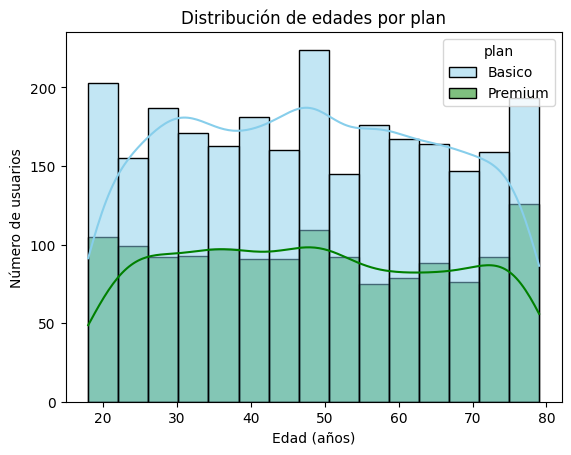

In [31]:
# Histograma para visualizar la edad (age)
sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=15,
    kde=True
)
plt.title('Distribución de edades por plan')
plt.xlabel('Edad (años)')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights: 

Distribución: las edades de los clientes abarcan aproximadamente de 18 a 79 años. El plan Básico presenta una mayor cantidad de usuarios en prácticamente todos los intervalos, mientras que el plan Premium tiene menos registros. En ambos planes, los clientes se distribuyen a lo largo de distintos rangos de edad, sin una concentración exclusiva en un grupo específico. Esto sugiere que ambos planes tienen usuarios de diferentes edades.

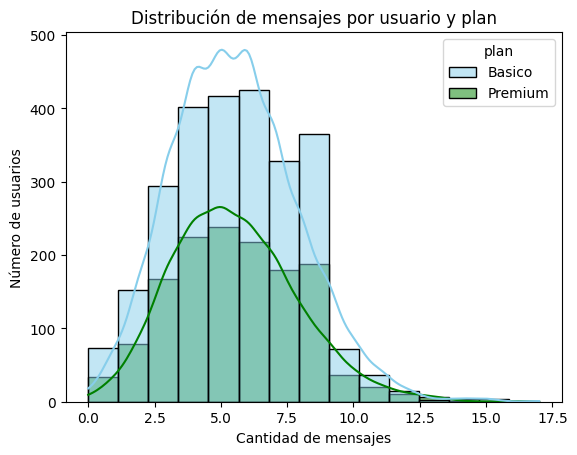

In [32]:

# Histograma para visualizar la cantidad de mensajes
sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=15,
    kde=True
)
plt.title('Distribución de mensajes por usuario y plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Número de usuarios')
plt.show()


💡Insights: 

Distribución: la mayoría de los usuarios registra aproximadamente entre 3 y 8 mensajes. El plan Básico presenta una mayor cantidad de usuarios en esos rangos, mientras que la distribución del plan Premium muestra una forma similar, pero con menos registros. Ambas distribuciones presentan una ligera asimetría hacia la derecha, con pocos usuarios que registran más de 10 mensajes. Esto sugiere que el consumo habitual se concentra en cantidades moderadas de mensajes.

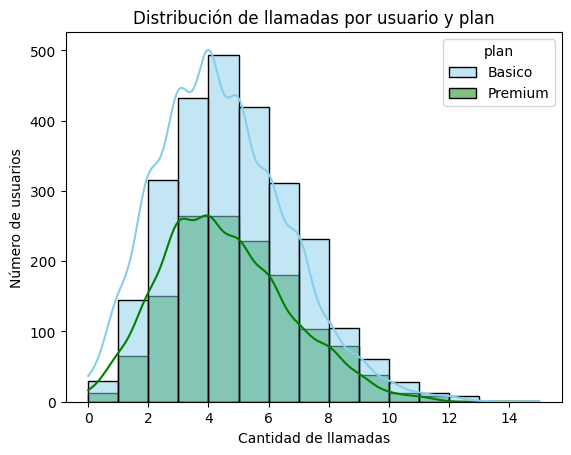

In [33]:
# Histograma para visualizar la cantidad de llamadas
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=15,
    kde=True
)
plt.title('Distribución de llamadas por usuario y plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights: 

Distribución: la mayoría de los usuarios realiza entre 3 y 7 llamadas. El plan Básico presenta una mayor cantidad de usuarios en estos intervalos, mientras que Premium muestra una distribución similar, pero con menos registros. La distribución presenta asimetría hacia la derecha, ya que la frecuencia disminuye a medida que aumenta la cantidad de llamadas. Se observan pocos usuarios con más de 10 llamadas, que podrían representar patrones de consumo menos frecuentes.

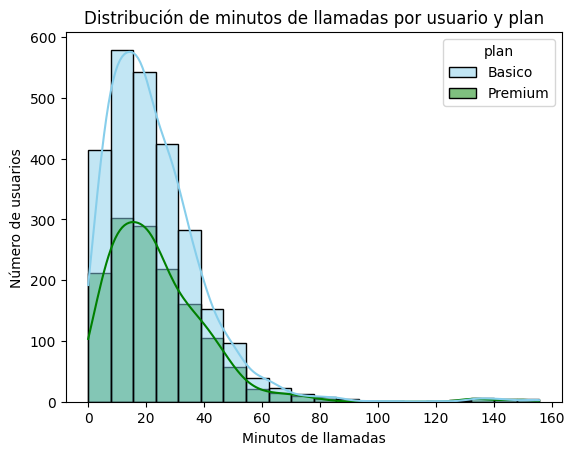

In [34]:

# Histograma para visualizar los minutos de llamadas
sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=20,
    kde=True
)
plt.title('Distribución de minutos de llamadas por usuario y plan')
plt.xlabel('Minutos de llamadas')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights: 

Distribución: la mayoría de los usuarios acumula aproximadamente entre 5 y 35 minutos de llamadas. El plan Básico presenta una mayor cantidad de usuarios en estos intervalos, mientras que Premium muestra una distribución similar, pero con menos registros. La distribución está sesgada hacia la derecha, ya que la frecuencia disminuye a medida que aumentan los minutos acumulados. Se observan algunos usuarios con consumos superiores a 80 minutos y casos extremos cercanos a 150 minutos, que conviene investigar mediante un análisis de outliers antes de determinar si son comportamientos inusuales o errores.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

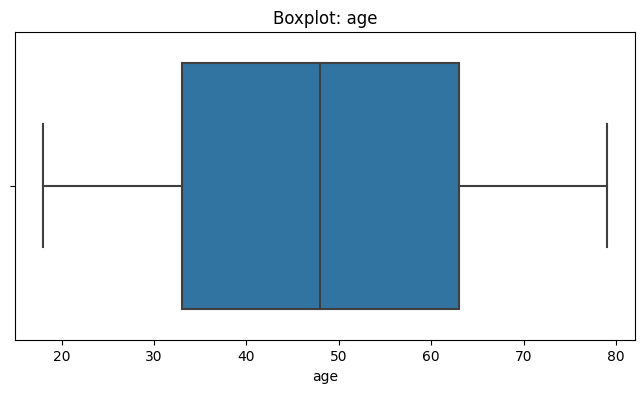

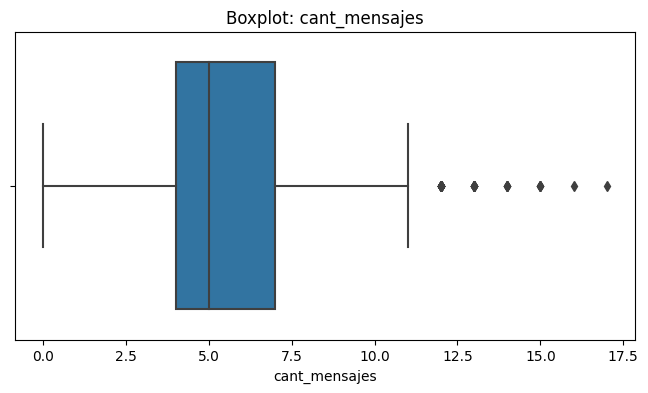

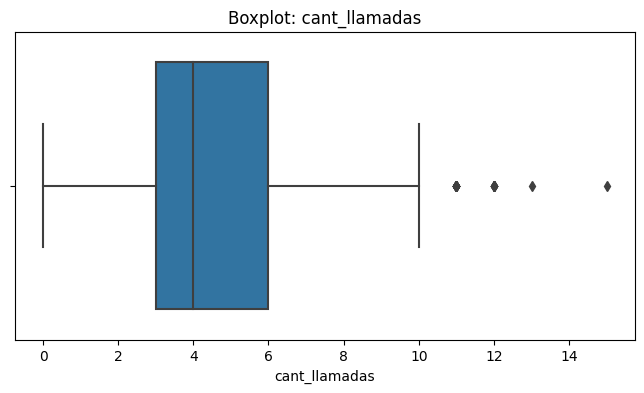

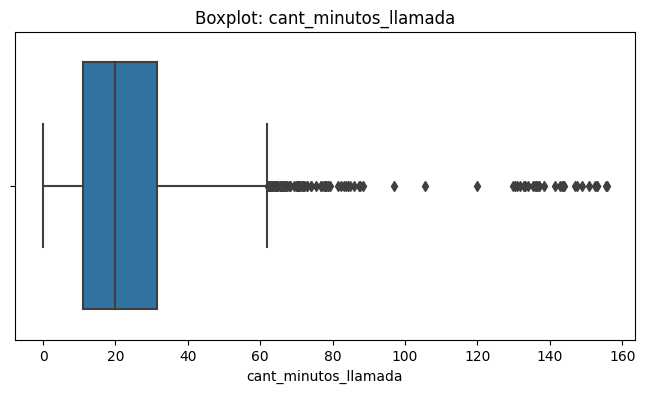

In [35]:
# Visualizando usando BoxPlot
columnas_numericas = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 

age: no se observan outliers en el boxplot. Las edades se encuentran aproximadamente entre 18 y 79 años y no se aprecian valores extremos fuera de los bigotes. Se recomienda conservar los registros.

cant_mensajes: se observan outliers por encima del límite superior, aproximadamente desde 12 hasta 17 mensajes. Se recomienda investigar estos usuarios, pero conservar los valores si corresponden a consumos reales.

cant_llamadas: se identifican outliers superiores, aproximadamente desde 11 hasta 15 llamadas. Se recomienda revisar los registros extremos y mantenerlos si representan comportamientos válidos.

cant_minutos_llamada: se observan numerosos outliers superiores, con valores que superan aproximadamente los 60 minutos y algunos cercanos a 155 minutos. La distribución presenta una clara asimetría hacia la derecha. Se recomienda investigar estos casos y conservarlos si son registros legítimos.


In [38]:
# Calcular límites con el método IQR
columnas_limites = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = user_profile[
        (user_profile[col] < limite_inferior) |
        (user_profile[col] > limite_superior)
    ]

    print(f"\nVariable: {col}")
    print(f"Límite inferior: {limite_inferior:.2f}")
    print(f"Límite superior: {limite_superior:.2f}")
    print(f"Cantidad de posibles outliers: {len(outliers)}")
    print(f"Valor máximo: {user_profile[col].max():.2f}")



Variable: age
Límite inferior: -12.00
Límite superior: 108.00
Cantidad de posibles outliers: 0
Valor máximo: 79.00

Variable: cant_mensajes
Límite inferior: -0.50
Límite superior: 11.50
Cantidad de posibles outliers: 46
Valor máximo: 17.00

Variable: cant_llamadas
Límite inferior: -1.50
Límite superior: 10.50
Cantidad de posibles outliers: 30
Valor máximo: 15.00

Variable: cant_minutos_llamada
Límite inferior: -19.32
Límite superior: 61.86
Cantidad de posibles outliers: 109
Valor máximo: 155.69


In [37]:

# Revisar los límites superiores y máximos
user_profile[columnas_limites].describe().round(2)


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.00,3999.00,3999.00,3999.00
mean,48.14,5.52,4.48,23.32
std,17.69,2.36,2.14,18.17
min,18.00,0.00,0.00,0.00
25%,33.00,4.00,3.00,11.12
50%,48.00,5.00,4.00,19.78
75%,63.00,7.00,6.00,31.42
max,79.00,17.00,15.00,155.69


💡Insights:

-cant_mensajes: mantener los outliers. Se identificaron 46 casos, con un máximo de 17 mensajes frente a una mediana de 5. Estos valores pueden representar clientes con mayor actividad y no necesariamente errores de registro.

-cant_llamadas: mantener los outliers. Se encontraron 30 casos, con un máximo de 15 llamadas frente a una mediana de 4. Se recomienda conservarlos si corresponden a consumos reales, ya que pueden reflejar necesidades particulares de los clientes.

-cant_minutos_llamada: mantener los outliers, pero revisar los casos extremos. Se identificaron 109 casos, con un máximo de 155,69 minutos frente a una mediana de 19,78. La diferencia es considerable, por lo que conviene verificar estos registros antes de considerarlos errores.

- los outliers de las variables de uso se conservarán para no perder información potencialmente relevante para el negocio. Solo se corregirán o excluirán registros si se encuentra evidencia de errores de captura o inconsistencias.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [40]:

import numpy as np

In [41]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) &
    (user_profile['cant_mensajes'] < 5),

    (user_profile['cant_llamadas'] < 10) &
    (user_profile['cant_mensajes'] < 10)
]

categorias = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(
    condiciones,
    categorias,
    default='Alto uso'
)

In [42]:
# Verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [43]:
# Crear columna grupo_edad
condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

categorias_edad = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(
    condiciones_edad,
    categorias_edad,
    default='Adulto Mayor'
)



In [44]:

# Verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

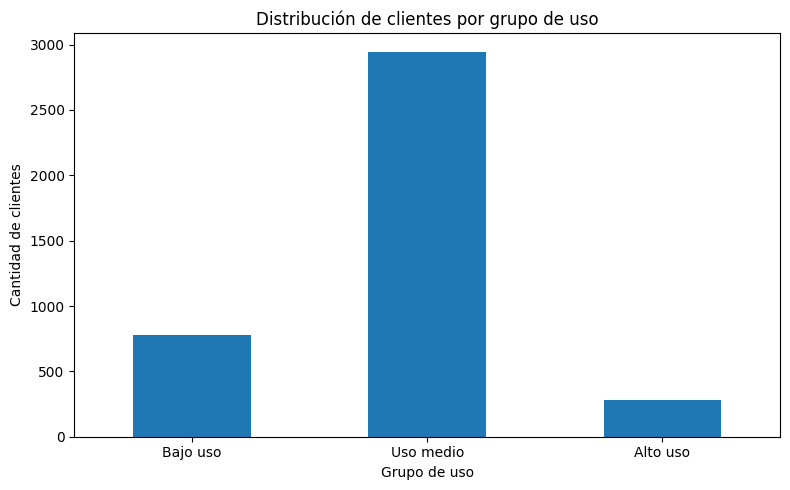

In [49]:

# Visualización de los segmentos por uso
conteo_uso = user_profile['grupo_uso'].value_counts().reindex(
    ['Bajo uso', 'Uso medio', 'Alto uso'],
    fill_value=0
)

plt.figure(figsize=(8, 5))
conteo_uso.plot(kind='bar')
plt.title('Distribución de clientes por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de clientes')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



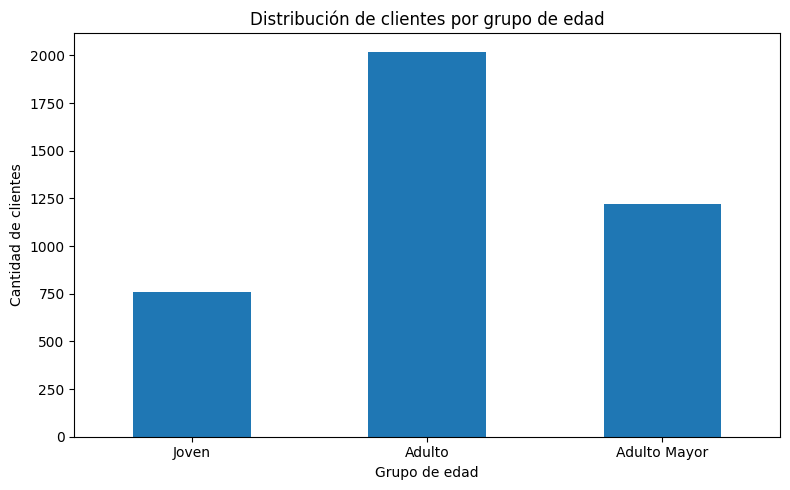

In [50]:
# Visualización de los segmentos por edad
conteo_edad = user_profile['grupo_edad'].value_counts().reindex(
    ['Joven', 'Adulto', 'Adulto Mayor'],
    fill_value=0
)

plt.figure(figsize=(8, 5))
conteo_edad.plot(kind='bar')
plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de clientes')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

Análisis ejecutivo — ConnectaTel

1. Calidad inicial de los datos

Durante la exploración se identificaron varios problemas de calidad. En users, la columna city tenía 469 valores nulos (11,72 %) y 96 registros con el valor ? (2,4 %), que se estandarizaron como valores faltantes. En age se encontró el sentinel -999, que se reemplazó por la mediana de las edades válidas. Además, se identificaron 40 fechas de registro de 2026, fuera del periodo de análisis hasta 2024, que se marcaron como fechas faltantes.

En usage, se encontraron 50 fechas nulas (0,125 %), 22.076 valores nulos en duration (55,19 %) y 17.896 en length (44,74 %). El análisis por tipo de actividad mostró que los nulos de estas dos últimas columnas están asociados principalmente a registros donde la variable no aplica: los mensajes no tienen duración de llamada y las llamadas no tienen longitud de mensaje. Por ello, se conservaron como nulos estructurales, sin imputarlos con cero.

2. Segmentos de clientes y comportamiento

La segmentación por edad identificó tres grupos: jóvenes (menores de 30 años), adultos (de 30 a 59 años) y adultos mayores (60 años o más). En la visualización, el grupo adulto fue el más numeroso, seguido de los adultos mayores y los jóvenes.

Por nivel de uso, la mayor parte de los clientes se clasificó como Uso medio, seguida de Bajo uso y Alto uso. Esta clasificación se basó en la cantidad de llamadas y mensajes registrados por cliente. Los segmentos permiten organizar futuras estrategias comerciales, aunque se necesita comparar el consumo por edad y plan para confirmar las diferencias de comportamiento entre grupos.

3. Segmentos potencialmente valiosos

Los clientes de alto uso pueden representar una oportunidad para ofrecer planes con mayores beneficios o paquetes adicionales, siempre que su consumo genere necesidades que la oferta actual no cubra. Los clientes de bajo uso podrían ser candidatos para campañas de activación, comunicación de beneficios o revisión de la adecuación de su plan.

El segmento adulto merece atención porque representa la mayor parte de la base de clientes. Sin embargo, no es posible afirmar que sea el segmento más rentable sin analizar ingresos, costos, permanencia y cancelaciones.

4. Patrones de uso extremo y outliers

El método IQR no identificó outliers en age. En las métricas de uso se encontraron 46 posibles outliers en cant_mensajes, 30 en cant_llamadas y 109 en cant_minutos_llamada. El máximo registrado fue de 17 mensajes, 15 llamadas y 155,69 minutos de llamadas por usuario.

Estos valores extremos no se eliminaron automáticamente, porque pueden representar consumos legítimos. Se recomienda revisar los casos de mayor duración para descartar errores de captura o comportamientos inusuales antes de tomar decisiones comerciales.

5. Recomendaciones comerciales

Evaluar los planes actuales: comparar llamadas, mensajes y minutos registrados con los beneficios incluidos en Básico y Premium para detectar clientes que podrían necesitar un plan diferente.

Activar a los clientes de bajo uso: probar campañas que comuniquen los beneficios disponibles y medir si aumenta el uso del servicio.

Atender a los clientes de alto uso: investigar si necesitan paquetes adicionales o mayores beneficios para evitar una mala experiencia por falta de capacidad incluida.

Personalizar las campañas por edad: evaluar diferencias de consumo entre jóvenes, adultos y adultos mayores antes de diseñar mensajes comerciales específicos.

Mejorar la calidad de los datos: investigar los registros con ciudades desconocidas, fechas fuera de rango y consumos extremos, documentando cada corrección.

Medir los resultados: evaluar las campañas con indicadores como consumo, ingresos por cliente, migración de plan y churn, siempre que se disponga de datos suficientes.

Conclusión ejecutiva

El análisis inicial permitió identificar problemas de calidad, describir la distribución de los clientes y construir segmentos por edad y nivel de uso. El grupo de uso medio y el segmento adulto concentran la mayor cantidad de clientes según las visualizaciones. Además, las métricas de consumo presentan valores extremos que requieren validación, especialmente en los minutos de llamadas.

ConnectaTel puede utilizar estos resultados como base para diseñar ofertas diferenciadas y mejorar la experiencia del cliente. Antes de implementar cambios definitivos, se recomienda profundizar en la comparación entre planes, edades, consumo e indicadores de churn y rentabilidad para priorizar las acciones con mayor impacto.

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- Se encontraron 469 valores nulos y 96 valores ? en city, equivalentes al 14,13 % de los 4.000 clientes. Se estandarizaron como valores faltantes.

- Se identificaron el sentinel -999 en age y 40 fechas de registro de 2026 fuera del periodo de análisis. Se corrigió la edad usando la mediana y se marcaron las fechas fuera de rango como nulas.

🔍 **Segmentos por Edad**

- El grupo Adulto (30 a 59 años) es el más numeroso, seguido de Adulto Mayor (60 años o más) y Joven (menores de 30 años).

- Esta distribución permite priorizar el análisis del grupo adulto y comparar sus patrones de consumo con los demás grupos para diseñar ofertas diferenciadas.

📊 **Segmentos por Nivel de Uso**


- El grupo Uso medio concentra la mayor cantidad de clientes, seguido de Bajo uso y Alto uso.

- Los clientes de bajo uso podrían ser candidatos para campañas de activación, mientras que los de alto uso podrían requerir beneficios adicionales, previa revisión de sus necesidades reales.


➡️ Esto sugiere que ConnectaTel puede mejorar la segmentación comercial combinando edad, nivel de uso y plan contratado. Antes de modificar los planes, es necesario comparar el consumo por segmento y verificar si existen diferencias en ingresos, permanencia y cancelaciones.


💡 **Recomendaciones**

- Diseñar campañas de activación para clientes de bajo uso y evaluar planes o paquetes adicionales para clientes de alto uso, midiendo los resultados de cada campaña.

-Investigar los valores extremos de consumo, especialmente los minutos de llamadas, y mejorar la calidad de los datos para tomar decisiones comerciales confiables.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`